In [1]:
import joblib
import numpy as np
import json
from copy import deepcopy
import jax
import pennylane as qml
import csv
import json
import os, sys
import pandas as pd
import shap
import jax.numpy as jnp
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import tensorflow as tf
import shap
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from cmcrameri import cm
from matplotlib.ticker import LogLocator, LogFormatter, FuncFormatter, NullFormatter
from joblib import Parallel, delayed
import re

sys.path.append('../')
from libs import dataloading, qnn_models, circuits
from libs.helpers import mix_with_white
plt.style.use('../libs/notebookstyle_aps.mplstyle')

%load_ext autoreload
%autoreload 2

I0000 00:00:1792178889.804080 3371701 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792178897.363989 3371701 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


/home/b/b309252/turbulence-parameterization-palm/notebooks


## Data loading

In [2]:
jnp_train_inputs, jnp_val_inputs, jnp_train_outputs, jnp_val_outputs = dataloading.load_data(0, n_samples = 'all')

In [3]:
# choose large values for accurate estimate with Kernel SHAP
background = np.array(jnp_train_inputs[:200])  
sample = np.array(jnp_val_inputs[:1000])

In [4]:
feature_names = ['$p$','$\\theta$','$z$/ABL','$u$','$v$','$w$']

## Shapley values of the classical NN

In [5]:
def shap_analysis_cl(model_name, j, save = True):
    
    model = tf.keras.models.load_model("./cl_models/%s_%i"%(model_name,j))
    
    explainer = shap.ExactExplainer(model, background)
    
    shap_values = explainer.shap_values(sample, nsamples=len(sample))[:,:,0]

    file_path = f'./cl_results/{model.name}_{j}_shap_exact.npz'
    if save:
        np.savez(file_path,     shap_values=shap_values)
    
    shap.summary_plot(shap_values, sample, feature_names=feature_names)


In [6]:
model_list_all = !ls './cl_models/'
model_list = [s for s in model_list_all if ((s[-2:] == '_1') and ('_' in s[:-2]))]
models = []
n_params = []
for model1 in model_list:
    model = tf.keras.models.load_model('./cl_models/' + model1)
    models += [model]
    n_params += [[model.name, model.count_params()]]
model_list_unique = [s[:-2] for s in model_list]

In [7]:
for j in range(1,11):
    for model_name in model_list_unique:
        file_path = f"./cl_results/{model_name}_{j}_shap_exact.npz"

        if not os.path.exists(file_path):
            shap_analysis_cl(model_name, j)
        else:        
            print(model_name, j, 'exists')

## Shapley values of the QNN

In [8]:
import re 
df = pd.read_csv('../results/QNN_results/QNN_r2.txt', header = 0)
def restore_key(s):
    values = [int(x) for x in re.findall(r"-?\d+", s)]
    return jnp.array(values, dtype=jnp.uint32)

keys = [restore_key(s) for s in df.key.unique()]

In [9]:
save_dir = '../results/QNN_results/'

def shap_analysis(n_enc, n_dec, n_qubits, local_observable, key, enc_angles, save = True):
    
    mycircuit = circuits.PQCircuit(n_enc, n_dec, n_qubits, var_angles = 'XYZ', encoding_angles=enc_angles, choose_freq = True)
        
    dev = qml.device("default.qubit", wires=n_qubits)
    
    model_qnn, no_params, model_name = qnn_models.make_model(dev, mycircuit, local_observable)

    file_path = f'{save_dir}{model_name}_shap{key}_exact.npz'

    if not os.path.exists(file_path):

        pars = np.load(f'{save_dir}{model_name}_optparams{key}.npz')['opt_params']
        
        circuit = mycircuit
        if local_observable:
                observable_indices = list(range(circuit.n_wires))
                obs_return = lambda: [qml.expval(qml.PauliZ(i)) for i in observable_indices]
        else:
            full_obs = reduce(lambda x, y: x @ y, [qml.PauliZ(i) for i in range(circuit.n_wires)])
            obs_return = lambda: [qml.expval(full_obs)]
                
        @qml.qnode(dev, interface="jax")
        def qnn_pqc(inputs, angles):
            circuit(inputs, angles,  dev.wires)
            return obs_return()
    
        def qnn_single(inputs, angles):
            inputs = inputs[None, :]
            out = qnn_pqc(inputs, angles)
            return out[0]
        
        qnn_batch = jax.vmap(lambda x: qnn_single(x, pars))

        #### need to redefine model for shapes of arrays to work out
        def qnn_shap_model(X):
            X = jnp.array(X)
        
            if X.ndim == 1:
                X = X[None, :]
        
            outputs = qnn_batch(X)
            return np.array(outputs)
        
        # For first qubit only
        def qnn_shap_model_single(X):
            return qnn_shap_model(X)[:, 0]
        
        explainer = shap.ExactExplainer(qnn_shap_model_single, background)
        
        shap_values = explainer.shap_values(sample, nsamples=len(sample))
        if save:
            np.savez(f'{save_dir}{model_name}_shap{key}_exact.npz', shap_values = shap_values)
        
        shap.summary_plot(shap_values, sample, feature_names=feature_names)

In [10]:
calc_qnn_shap = False
def run_one_shap(n_enc, n_dec, n_qubits, enc_angles, local_observable, key_j):
    try:
        shap_analysis(
            n_enc,
            n_dec,
            n_qubits,
            local_observable,
            key_j,
            enc_angles,
        )
        return True
    except Exception as e:
        print(
            f"nonexistent or failed: nq={n_qubits}, enc={n_enc}, dec={n_dec}, "
            f"local={local_observable}, key={key_j}"
        )
        return False

if calc_qnn_shap:
    tasks = [
        (n_enc, n_dec, n_qubits, enc_angles, local_observable, key_j)
        for [n_qubits, enc_angles] in [[2,"XYZ"],[3,"XY"],[4,"XYZ"],[6,"X"], [6,"XY"], [8, 'XY']]
        for n_enc in range(1, 10)
        for n_dec in range(1, 10)
        for local_observable in [0, 1]
        for key_j in keys
    ]
    
    n_jobs = int(os.environ.get("SLURM_CPUS_PER_TASK", os.cpu_count() // 2))
    
    results = Parallel(
        n_jobs=n_jobs,
        backend="loky",
        verbose=10,
    )(
        delayed(run_one_shap)(*task) for task in tasks
    )
    
    
    n_fail = results.count(False)
    print("Done.")


## Figure

In [11]:
model_list_all = !ls '../results/cl_models/'
model_list_2 = [s for s in model_list_all if (s[-2:] == '_1')]
models = []
n_params = []
n_layers = []
model_list_unique = []
for model1 in model_list_2:
    model = tf.keras.models.load_model('../results/cl_models/' + model1)
    models += [model]
    n_params += [[model.name, model.count_params()]]
    n_layers += [[model.name,len(model.layers)]]
    model_list_unique += [model.name]
    model.summary()

Model: "sequential_100"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_313 (Dense)           (None, 3)                 21        
                                                                 
 dense_314 (Dense)           (None, 1)                 4         
                                                                 
Total params: 25 (100.00 Byte)
Trainable params: 25 (100.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


E0000 00:00:1792178911.883553 3371701 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential_101"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_315 (Dense)           (None, 41)                287       
                                                                 
 dense_316 (Dense)           (None, 34)                1428      
                                                                 
 dense_317 (Dense)           (None, 5)                 175       
                                                                 
 dense_318 (Dense)           (None, 7)                 42        
                                                                 
 dense_319 (Dense)           (None, 1)                 8         
                                                                 
Total params: 1940 (7.58 KB)
Trainable params: 1940 (7.58 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
Model: "sequential_1

In [12]:
save_dir_cl = '../results/cl_results/'
feature_names = ['$\\tilde{p}$','$\\tilde{\\theta}$','$\\tilde{z_{\\rm rel}}$','$\\tilde{u}$','$\\tilde{v}$','$\\tilde{w}$']

In [13]:
rows = []

for model_name in model_list_unique:
        per_j_feature_means = []
    
        for j in range(1, 11):
            path = f'{save_dir_cl}{model_name}_{j}_shap_exact.npz'
            shap = np.load(path)['shap_values']
    
            feature_mean = np.mean(np.abs(shap), axis=0)  # (n_features,)
            per_j_feature_means.append(feature_mean)
    
        per_j_feature_means = np.array(per_j_feature_means)  # (10, n_features)
    
        mean_over_j = np.mean(per_j_feature_means, axis=0)
        std_over_j = np.std(per_j_feature_means, axis=0)
    
        for i, (mu, sigma) in enumerate(zip(mean_over_j, std_over_j)):
            rows.append({
                "model": model_name,
                "n_params":dict(n_params)[model_name],
                "n_layers":dict(n_layers)[model_name],
                "feature": feature_names[i],
                "mean_shap": mu,
                "std_shap": sigma
            })

df_shap_cl = pd.DataFrame(rows)
df_shap_cl

,model,n_params,n_layers,feature,mean_shap,std_shap
0,sequential_100,25,2,$\tilde{p}$,0.034286,0.015129
1,sequential_100,25,2,$\tilde{\theta}$,0.008143,0.010477
2,sequential_100,25,2,$\tilde{z_{\rm rel}}$,0.301765,0.045509
3,sequential_100,25,2,$\tilde{u}$,0.022169,0.008819
4,sequential_100,25,2,$\tilde{v}$,0.022878,0.007021
...,...,...,...,...,...,...
247,sequential_30,49,2,$\tilde{\theta}$,0.028736,0.011985
248,sequential_30,49,2,$\tilde{z_{\rm rel}}$,0.315058,0.004566
249,sequential_30,49,2,$\tilde{u}$,0.029510,0.005183
250,sequential_30,49,2,$\tilde{v}$,0.021062,0.002339


In [14]:
rows = []

for model_name in model_list_unique:
        for j in range(1, 11):  # runs
            path = f"{save_dir_cl}{model_name}_{j}_shap_exact.npz"
            shap = np.load(path)["shap_values"]  # (n_samples, n_features)
    
            feature_shap = np.mean(np.abs(shap), axis=0)  # (n_features,)
    
            for i, val in enumerate(feature_shap):
                rows.append({
                    "model_name": model_name,
                    "key": j,
                    "n_params": dict(n_params)[model_name],
                    "n_layers": dict(n_layers)[model_name],
                    "feature": feature_names[i],
                    "single_shap": val,
                })

df_shap_cl_single = pd.DataFrame(rows)


In [15]:
df = pd.read_csv('../results/QNN_results/QNN_r2.txt', header=0)

def key_to_str(key):
    return "key_" + "_".join(str(int(x)) for x in np.asarray(key).ravel())

def restore_key(s):
    # handles the new clean format ("key_1234_5678") and any legacy
    # "Array([1234, 5678], dtype=uint32)" strings (only the bracketed
    # values are read, so 'uint32' can't leak in as a third element)
    s = str(s)
    m = re.search(r"key_([0-9_]+)", s)
    if not m:
        m = re.search(r"\[([0-9_,\s]+)\]", s)
    if not m:
        m = re.search(r"([0-9_,\s]+)", s)
    return jnp.array([int(x) for x in re.findall(r"\d+", m.group(1))], dtype=jnp.uint32)

keys = [restore_key(s) for s in df.key.unique()]

rows = []
save_dir_qu = '../results/QNN_results/'
var_angles = 'XYZ'
n_missing = 0

for [n_qubits, encoding_angles] in [[2,"XYZ"],[3,"XY"],[4,"XYZ"],[6,"X"],[6,"XY"],[8,"XY"]]:
    for n_enc in range(1,10):
        for n_dec in range(0,10):
            for local_observable in [0,1]:
                model_name = (str(n_qubits) + 'qubits_' + 'circuit_' + encoding_angles + '_'
                              + var_angles + '_freq' + str(n_enc) + 'enc_'
                              + str(n_dec) + 'dec_' + ('' if local_observable else 'non') + 'local')

                per_j_feature_means = []
                for key_j in keys:
                    f = f'{save_dir_qu}{model_name}_shap{key_to_str(key_j)}_exact.npz'
                    if not os.path.exists(f):
                        continue
                    shap = np.load(f)['shap_values']
                    per_j_feature_means.append(np.mean(np.abs(shap), axis=0))   # (n_features,)

                if not per_j_feature_means:
                    n_missing += 1
                    print(n_qubits, encoding_angles, n_enc, n_dec, local_observable, 'no shap files')
                    continue

                per_j_feature_means = np.array(per_j_feature_means)              # (n_keys, n_features)
                if per_j_feature_means.ndim == 1:
                    per_j_feature_means = per_j_feature_means[np.newaxis, :]

                mean_over_j = per_j_feature_means.mean(axis=0)
                std_over_j  = per_j_feature_means.std(axis=0)

                for i, (mu, sigma) in enumerate(zip(mean_over_j, std_over_j)):
                    rows.append({
                        "model": model_name,
                        "feature": feature_names[i],
                        "mean_shap": mu,
                        "std_shap": sigma,
                        "n_keys": len(per_j_feature_means),
                    })

print(f"models with no shap files: {n_missing}")
df_shap_qu = pd.DataFrame(rows)
df_shap_qu

2 XYZ 1 5 0 no shap files
2 XYZ 1 5 1 no shap files
2 XYZ 1 6 0 no shap files
2 XYZ 1 6 1 no shap files
2 XYZ 1 7 0 no shap files
2 XYZ 1 7 1 no shap files
2 XYZ 1 8 0 no shap files
2 XYZ 1 8 1 no shap files
2 XYZ 1 9 0 no shap files
2 XYZ 1 9 1 no shap files
2 XYZ 2 5 0 no shap files
2 XYZ 2 5 1 no shap files
2 XYZ 2 6 0 no shap files
2 XYZ 2 6 1 no shap files
2 XYZ 2 7 0 no shap files
2 XYZ 2 7 1 no shap files
2 XYZ 2 8 0 no shap files
2 XYZ 2 8 1 no shap files
2 XYZ 2 9 0 no shap files
2 XYZ 2 9 1 no shap files
2 XYZ 3 5 0 no shap files
2 XYZ 3 5 1 no shap files
2 XYZ 3 6 0 no shap files
2 XYZ 3 6 1 no shap files
2 XYZ 3 7 0 no shap files
2 XYZ 3 7 1 no shap files
2 XYZ 3 8 0 no shap files
2 XYZ 3 8 1 no shap files
2 XYZ 3 9 0 no shap files
2 XYZ 3 9 1 no shap files
2 XYZ 4 5 0 no shap files
2 XYZ 4 5 1 no shap files
2 XYZ 4 6 0 no shap files
2 XYZ 4 6 1 no shap files
2 XYZ 4 7 0 no shap files
2 XYZ 4 7 1 no shap files
2 XYZ 4 8 0 no shap files
2 XYZ 4 8 1 no shap files
2 XYZ 4 9 0 

,model,feature,mean_shap,std_shap,n_keys
0,2qubits_circuit_XYZ_XYZ_freq1enc_0dec_nonlocal,$\tilde{p}$,5.441444e-02,2.778486e-03,10
1,2qubits_circuit_XYZ_XYZ_freq1enc_0dec_nonlocal,$\tilde{\theta}$,1.610090e-08,5.832700e-10,10
2,2qubits_circuit_XYZ_XYZ_freq1enc_0dec_nonlocal,$\tilde{z_{\rm rel}}$,3.266153e-01,1.983742e-03,10
3,2qubits_circuit_XYZ_XYZ_freq1enc_0dec_nonlocal,$\tilde{u}$,1.565643e-08,9.682542e-10,10
4,2qubits_circuit_XYZ_XYZ_freq1enc_0dec_nonlocal,$\tilde{v}$,4.888953e-03,5.495933e-04,10
...,...,...,...,...,...
2875,8qubits_circuit_XY_XYZ_freq5enc_0dec_local,$\tilde{\theta}$,3.526828e-02,1.130362e-03,10
2876,8qubits_circuit_XY_XYZ_freq5enc_0dec_local,$\tilde{z_{\rm rel}}$,3.139349e-01,4.632290e-03,10
2877,8qubits_circuit_XY_XYZ_freq5enc_0dec_local,$\tilde{u}$,3.280198e-02,4.869132e-03,10
2878,8qubits_circuit_XY_XYZ_freq5enc_0dec_local,$\tilde{v}$,2.184692e-02,3.204591e-03,10


In [16]:
def parse_config(s):
    match = re.match(r"(\d+)qubits_circuit_([a-zA-Z]+)_([a-zA-Z]+)_freq(\d+)enc_(\d+)dec_([a-zA-Z]+)", s)
    if match:
        qubits, enc_angles, angles, n_enc, n_dec,  entanglement = match.groups()
        return int(qubits), int(n_enc), int(n_dec), entanglement, angles, enc_angles
    return None, None, None, None

df_shap_qu[['n_qubits', 'n_enc', 'n_dec', 'entanglement','angles','enc_angles']] = df_shap_qu['model'].apply(
    lambda x: pd.Series(parse_config(x))
)

def getpars(df):
    return df.n_qubits*(df.n_enc + df.n_dec)*df.angles.apply(lambda s: len(s)) + df.n_qubits*df.n_enc*df.enc_angles.apply(lambda s: len(s))

df_shap_qu['nonlocal'] = (df_shap_qu.entanglement == 'nonlocal')*1.
df_shap_qu['n_params'] = getpars(df_shap_qu)

In [17]:
rows = []
save_dir_qu = "../results/QNN_results/"
var_angles = "XYZ"

def key_to_str(key):
    return "key_" + "_".join(str(int(x)) for x in np.asarray(key).ravel())

n_missing = 0
for [n_qubits, encoding_angles] in [[2,"XYZ"],[3,"XY"],[4,"XYZ"],[6,"X"],[6,"XY"],[8,"XY"]]:
    for n_enc in range(1, 10):
        for n_dec in range(0, 10):
            for local_observable in [0, 1]:
                model_name = (
                    f"{n_qubits}qubits_circuit_"
                    f"{encoding_angles}_{var_angles}_"
                    f"freq{n_enc}enc_{n_dec}dec_"
                    f"{'' if local_observable else 'non'}local"
                )
                for key in keys:
                    path = f"{save_dir_qu}{model_name}_shap{key_to_str(key)}_exact.npz"
                    if not os.path.exists(path):
                        n_missing += 1
                        continue
                    try:
                        shap = np.load(path)["shap_values"]
                        feature_shap = np.mean(np.abs(shap), axis=0)   # (n_features,)
                        for i, val in enumerate(feature_shap):
                            rows.append({
                                "model_name": model_name,
                                "key": key_to_str(key),
                                "n_qubits": n_qubits,
                                "n_enc": n_enc,
                                "n_dec": n_dec,
                                "local_observable": local_observable,
                                "feature": feature_names[i],
                                "single_shap": val,
                            })
                    except Exception as e:
                        print(model_name, key_to_str(key), e)
print(f"missing shap files skipped: {n_missing}")

df_shap_qu_single = pd.DataFrame(rows)
# keep only models that also made it into the aggregated table (df_shap_qu)
df_shap_qu_single = df_shap_qu_single[
    np.isin(df_shap_qu_single.model_name, df_shap_qu.model.values)
]
df_shap_qu_single

missing shap files skipped: 6000


,model_name,key,n_qubits,n_enc,n_dec,local_observable,feature,single_shap
0,2qubits_circuit_XYZ_XYZ_freq1enc_0dec_nonlocal,key_1220103521_3186102496,2,1,0,0,$\tilde{p}$,5.186221e-02
1,2qubits_circuit_XYZ_XYZ_freq1enc_0dec_nonlocal,key_1220103521_3186102496,2,1,0,0,$\tilde{\theta}$,1.581831e-08
2,2qubits_circuit_XYZ_XYZ_freq1enc_0dec_nonlocal,key_1220103521_3186102496,2,1,0,0,$\tilde{z_{\rm rel}}$,3.272196e-01
3,2qubits_circuit_XYZ_XYZ_freq1enc_0dec_nonlocal,key_1220103521_3186102496,2,1,0,0,$\tilde{u}$,1.462433e-08
4,2qubits_circuit_XYZ_XYZ_freq1enc_0dec_nonlocal,key_1220103521_3186102496,2,1,0,0,$\tilde{v}$,5.053488e-03
...,...,...,...,...,...,...,...,...
28795,8qubits_circuit_XY_XYZ_freq5enc_0dec_local,key_995714853_1645473629,8,5,0,1,$\tilde{\theta}$,3.535619e-02
28796,8qubits_circuit_XY_XYZ_freq5enc_0dec_local,key_995714853_1645473629,8,5,0,1,$\tilde{z_{\rm rel}}$,3.180326e-01
28797,8qubits_circuit_XY_XYZ_freq5enc_0dec_local,key_995714853_1645473629,8,5,0,1,$\tilde{u}$,3.471196e-02
28798,8qubits_circuit_XY_XYZ_freq5enc_0dec_local,key_995714853_1645473629,8,5,0,1,$\tilde{v}$,2.387133e-02


342 max params of the QNN


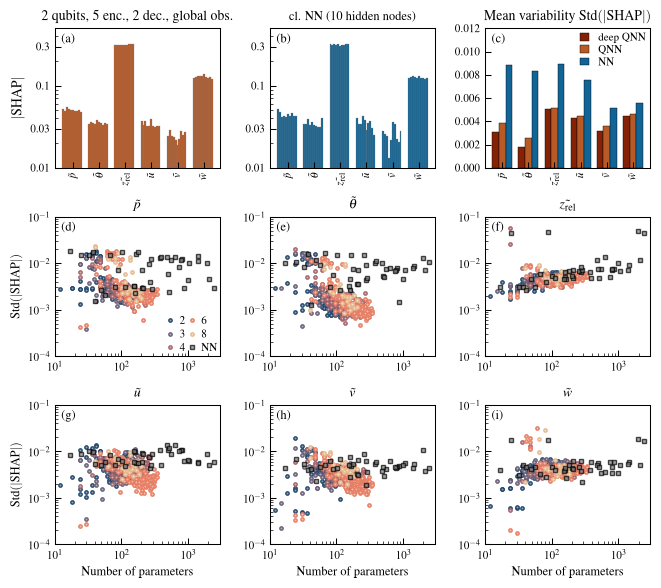

In [18]:
COLOR_QU = cm.vik(0.8)
COLOR_QU2 = cm.vik(0.9)
COLOR_CL = cm.vik(0.2)

fig = plt.figure(figsize=(6.77, 6))

gs = gridspec.GridSpec(
    3, 3,
    hspace=0.35,
    wspace=0.30
)

ax_a = fig.add_subplot(gs[0, 0])
ax_b = fig.add_subplot(gs[0, 1])
ax_c = fig.add_subplot(gs[0, 2])

# example models
QU_MODEL = "2qubits_circuit_XYZ_XYZ_freq5enc_2dec_nonlocal"
CL_MODEL = "sequential_133"

df_qu_ex = df_shap_qu_single.query("model_name == @QU_MODEL").copy()
df_cl_ex = df_shap_cl_single.query("model_name == @CL_MODEL").copy()

def canon_key(k):
    return tuple(np.asarray(k).ravel())

df_qu_ex["key_canon"] = df_qu_ex["key"].apply(canon_key)
df_cl_ex["key_canon"] = df_cl_ex["key"].apply(canon_key)

qu_keys = df_qu_ex["key_canon"].unique()
cl_keys = df_cl_ex["key_canon"].unique()

features = df_qu_ex["feature"].unique()
x = np.arange(len(features))

# compute variability
std_qu = (
    df_shap_qu_single
    .groupby(["model_name", "feature"])["single_shap"]
    .std()
    .groupby("feature")
    .mean()
    .reindex(features)
)

std_qu_deep = (
    df_shap_qu_single[(df_shap_qu_single.n_enc + df_shap_qu_single.n_dec) > 3]
    .groupby(["model_name", "feature"])["single_shap"]
    .std()
    .groupby("feature")
    .mean()
    .reindex(features)
)

std_cl = (
    df_shap_cl_single[df_shap_cl_single.n_params <= df_shap_qu.n_params.max()]
    .groupby(["model_name", "feature"])["single_shap"]
    .std()
    .groupby("feature")
    .mean()
    .reindex(features)
)

print(df_shap_qu.n_params.max(), 'max params of the QNN')


width = 0.75 / len(qu_keys)

for i, key in enumerate(qu_keys):
    vals = (
        df_qu_ex[df_qu_ex.key_canon == key]
        .set_index("feature")
        .reindex(features)["single_shap"]
    )
    ax_a.bar(
        x - 0.375 + i * width,
        vals,
        width=width,
        color=COLOR_QU,
        edgecolor="grey",
        linewidth = 0.2
    )

ax_a.set_title("2 qubits, 5 enc., 2 dec., global obs.")
ax_a.set_ylabel(r"$|\mathrm{SHAP}|$")


for i, key in enumerate(cl_keys):
    vals = (
        df_cl_ex[df_cl_ex.key_canon == key]
        .set_index("feature")
        .reindex(features)["single_shap"]
    )
    ax_b.bar(
        x - 0.375 + i * width,
        vals,
        width=width,
        color=COLOR_CL,
        edgecolor="grey",
        linewidth = 0.2
    )

ax_b.set_title("cl. NN (10 hidden nodes)", fontsize=9)


w = 0.38*2/3
ax_c.bar(x - w, std_qu_deep, w, color=COLOR_QU2, edgecolor="black", linewidth=0.3, label="deep QNN")
ax_c.bar(x , std_qu, w, color=COLOR_QU, edgecolor="black", linewidth=0.3, label="QNN")
ax_c.bar(x + w, std_cl, w, color=COLOR_CL, edgecolor="black", linewidth=0.3, label="NN")
ax_c.set_ylim(0,0.01)

ax_c.set_ylabel("Std |SHAP| over repetitions")
ax_c.set_title(r"Mean variability $\mathrm{Std}(|\mathrm{SHAP}|)$")
ax_c.legend(loc="upper right",
    frameon=False,
    labelcolor=None, borderpad=0.2,
    labelspacing=0.2, handlelength=0.8,
    borderaxespad=0.2
           )

features1 = np.array(['$\\tilde{p}$', '$\\tilde{\\theta}$', '$\\tilde{z_{\\rm rel}}$', '$\\tilde{u}$', '$\\tilde{v}$', '$\\tilde{w}$'])


for ax in [ax_a, ax_b, ax_c]:
    ax.set_xticks(x)
    ax.set_xticklabels(features1, rotation=90)
    ax.set_xlabel("") 
    
for ax in [ax_a, ax_b]:
    ax.set_ylim(0.01,0.5)

ax_b.set_ylabel("")
ax_c.set_ylabel("")

for ax in [ax_a, ax_b]:
    ax.set_yscale('log')
    ax.yaxis.set_major_locator( LogLocator(base=10, subs=(1,3)))
    ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x:g}"))
    ax.yaxis.set_minor_locator(LogLocator(base=10, subs=(2, 4, 5, 6, 7, 8, 9)))
    ax.yaxis.set_minor_formatter(NullFormatter())

ax_c.set_ylim(0,0.012)
if 0:
    ax_c.set_yscale('log')
    ax_c.set_ylim(0.0015,0.015)
    ax_c.yaxis.set_major_locator( LogLocator(base=10, subs=(1,6,3)))
    ax_c.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}"))
    ax_c.yaxis.set_minor_locator(LogLocator(base=10, subs=(2, 4, 5, 7, 8, 9)))
    ax_c.yaxis.set_minor_formatter(NullFormatter())

qubit_groups = sorted(df_shap_qu['n_qubits'].unique())
colors_qu = cm.lipari(np.linspace(0.15, 0.85, len(qubit_groups)))

for i, feat in enumerate(features):
    ax = fig.add_subplot(gs[1 + i // 3, i % 3])


    
    for c, nq in zip(colors_qu, qubit_groups):

        
        sub_qu = df_shap_qu[
            (df_shap_qu['feature'] == feat) &
            (df_shap_qu['n_qubits'] == nq)
        ]
        if len(sub_qu) == 0:
            continue

        ax.plot(
            sub_qu['n_params'],
            sub_qu['std_shap'],
            'o',
            color=c,
            markersize=2.4,
            markerfacecolor = mix_with_white(c,0.5),
            alpha=1,
            label=f'{nq}' if i == 0 else None,
        )

    sub_nn = df_shap_cl[(df_shap_cl['feature'] == feat)]
    ax.plot(
        sub_nn['n_params'],
        sub_nn['std_shap'],
        's',
        color='k',
        markersize=2.17,
        markerfacecolor = mix_with_white('k',0.5),
        alpha = .7,
        label='NN' if i == 0 else None,
    )

    

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(10, 3e3)
    ax.set_ylim(1e-4,.1)
    ax.set_title(feat)


    if np.isin(i,[3,4,5]):
        ax.set_xlabel("Number of parameters", fontsize=9)
    else:
        ax.set_xlabel("")

    if i % 3 == 0:
        ax.set_ylabel(r"$\mathrm{Std}(|\mathrm{SHAP}|)$", fontsize=9)
    else:
        ax.set_ylabel("")

    #ax.tick_params(labelsize=8)


handles, labels = fig.axes[3].get_legend_handles_labels()
fig.axes[3].legend(
    handles,
    labels,
    loc="lower right",
    frameon=False,
    ncol = 2,
    labelcolor=None, borderpad=0.2,
    labelspacing=0.3, handlelength=0.15, handleheight=None, handletextpad=None,
    borderaxespad=0.05, columnspacing=0.5, 
)


plt.subplots_adjust(
    left=0.10,
    right=0.98,
    bottom=0.07,
    top=0.93,
)

for ax, lab in zip(fig.axes, ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)", "(g)", "(h)", "(i)"]):
    ax.text(0.04, 0.96, lab, transform=ax.transAxes,
            va="top", ha="left", fontsize=9)

fig.savefig("../figures/shap_9panel.pdf")

<Axes: xlabel='feature'>

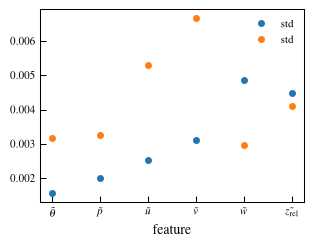

In [19]:
df_qu_ex.groupby('feature').single_shap.aggregate(['std']).plot(ax = plt.gca(), linestyle = '', marker = 'o')
df_cl_ex.groupby('feature').single_shap.aggregate(['std']).plot(ax = plt.gca(), linestyle = '', marker = 'o')

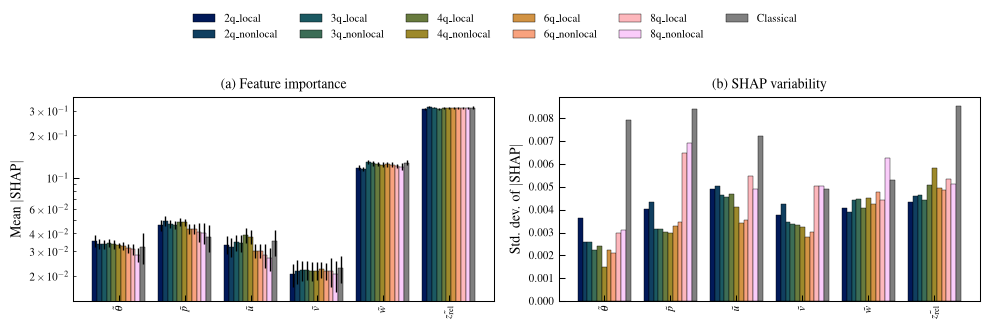

In [20]:
# -------------------------------
# ALL-IN-ONE CELL
# -------------------------------
import numpy as np
import matplotlib.pyplot as plt
from cmcrameri import cm

# -------------------------------
# Filter data
# -------------------------------
df_shap_f    = df_shap_cl.query("0 <= n_params <= 342").copy()
df_shap_qu_f = df_shap_qu.query("0 <= n_params <= 342").copy()

# -------------------------------
# Create condition label (qubits + observable)
# -------------------------------
df_shap_qu_f["condition"] = (
    df_shap_qu_f["n_qubits"].astype(str) + "q_" +
    df_shap_qu_f["entanglement"].astype(str)
)

# -------------------------------
# Aggregate quantum data
# -------------------------------
mean_qu = (
    df_shap_qu_f.groupby(["feature", "condition"])["mean_shap"]
    .mean()
    .unstack()
)

std_qu = (
    df_shap_qu_f.groupby(["feature", "condition"])["std_shap"]
    .mean()
    .unstack()
)

# -------------------------------
# Aggregate classical baseline
# -------------------------------
mean_cl = df_shap_f.groupby("feature")["mean_shap"].mean()
std_cl  = df_shap_f.groupby("feature")["std_shap"].mean()

# Ensure same feature order
features = mean_qu.index
mean_cl = mean_cl.reindex(features)
std_cl  = std_cl.reindex(features)

conditions = mean_qu.columns

# -------------------------------
# Plot setup
# -------------------------------
x = np.arange(len(features))
n_cond = len(conditions)
width = 0.8 / (n_cond + 1)

colors = cm.batlow(np.linspace(0, 1, n_cond))

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharex=True)

# -------------------------------
# (a) Mean |SHAP|
# -------------------------------
for i, cond in enumerate(conditions):
    axes[0].bar(
        x + (i - n_cond/2)*width,
        mean_qu[cond],
        width,
        yerr=std_qu[cond],
        color=colors[i],
        label=cond,
        edgecolor="black",
        linewidth=0.3,
    )

# Classical baseline
axes[0].bar(
    x + (n_cond/2)*width,
    mean_cl,
    width,
    yerr = std_cl,
    color="gray",
    label="Classical",
    edgecolor="black",
    linewidth=0.3,
)

axes[0].set_ylabel(r"Mean $|\mathrm{SHAP}|$")
axes[0].set_title("(a) Feature importance")
axes[0].set_yscale('log')

# -------------------------------
# (b) Std deviation
# -------------------------------
for i, cond in enumerate(conditions):
    axes[1].bar(
        x + (i - n_cond/2)*width,
        std_qu[cond],
        width,
        color=colors[i],
        edgecolor="black",
        linewidth=0.3,
    )

axes[1].bar(
    x + (n_cond/2)*width,
    std_cl,
    width,
    color="gray",
    edgecolor="black",
    linewidth=0.3,
)

#axes[1].set_yscale("log")
axes[1].set_ylabel(r"Std. dev. of $|\mathrm{SHAP}|$")
axes[1].set_title("(b) SHAP variability")
#axes[1].set_ylim(1e-3,)
# -------------------------------
# Formatting
# -------------------------------
for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(features, rotation=90)
    #ax.grid()

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=min(6, len(labels)),
    frameon=False,
    bbox_to_anchor=(0.5, 1.1),
)

plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.show()